# Dedo Verde — estufa em lugar inóspito (parte 1: simulador)

Uma estufa isolada precisa produzir comida de verdade com **pouca água**. Dois canteiros:

- **Milho** — calorias. Bebe muito, gosta de calor.
- **Feijão-caupi** (feijão-de-corda, do semiárido) — proteína. Aguenta seca, **não tolera encharcamento**.

O ar é **compartilhado** (aquecimento e ventilação valem para a estufa inteira), então a temperatura precisa ser um meio-termo: as faixas ideais só se cruzam entre **24 e 28 °C**. A água é **separada** por canteiro, mas sai de um único **tanque** que só enche com chuva. Na seca, o agente precisa fazer **triagem**: qual canteiro salvar?

O sol aquece de graça e seca o substrato; antes de chover as nuvens fecham, a luz cai e a estufa esfria. Energia e água ficam amarradas: com sol sobra calor e falta água, com chuva o tanque enche e a estufa esfria.

**Escolhas fixas:** 1 passo = 1 hora; episódio = 30 dias (720 passos) da fase de floração, quando a falta de água mais prejudica a colheita; γ = 0,99.

Este notebook tem: (1) parâmetros, (2) clima, (3) o ambiente Gymnasium, (4) checagem e linhas de base (aleatória e termostato). O DQN entra na parte 2.

In [ ]:
!pip install -q gymnasium stable-baselines3

## 1. Culturas e parâmetros

Tudo o que é número fica aqui, para calibrar sem mexer no resto. As faixas são aproximadas, de referência para a floração. Para acrescentar uma 3ª cultura (por exemplo, batata-doce), basta acrescentar um dicionário em `CULTURAS`: o espaço de ações cresce sozinho (2ᴺ × 9).

In [ ]:
import numpy as np
import gymnasium as gym
from gymnasium import spaces

# ---------------------------------------------------------------
# Culturas: cada canteiro tem uma. Para acrescentar uma 3ª cultura,
# basta acrescentar um dicionário (o espaço de ações cresce sozinho).
# Faixas aproximadas de referência para a fase de floração.
#   T_*: temperatura do ar (°C), compartilhada pela estufa
#   M_*: umidade do substrato (%), uma por canteiro
#   kc : quanto a cultura "bebe" em relação à evaporação de referência
# ---------------------------------------------------------------
CULTURAS = [
    dict(nome="milho",
         T_ideal=(24, 30), T_crit=(10, 38),
         M_ideal=(60, 85), M_crit=(30, 98),
         kc=1.2, M_ini=(65, 80)),
    dict(nome="feijão-caupi",
         T_ideal=(20, 28), T_crit=(12, 36),
         M_ideal=(45, 70), M_crit=(25, 90),   # não tolera encharcamento
         kc=0.7, M_ini=(50, 65)),
]

CONFIG = dict(
    # tempo
    dias=30,                 # 1 passo = 1 hora -> 720 passos
    # água
    tanque_cap=1500.0,       # litros
    tanque_ini=(0.5, 0.9),   # fração inicial sorteada
    irrig_litros=25.0,       # litros/hora por canteiro irrigado
    irrig_umid=8.0,          # pontos de umidade/hora por canteiro irrigado
    area_captacao=20.0,      # m² de telhado: 1 mm de chuva = 20 L
    # clima externo (lugar inóspito: dias quentes, noites frias)
    T_ext_media=18.0, T_ext_amp=8.0,
    p_seco_seco=0.85,        # persistência do regime seco (dia a dia)
    p_umido_umido=0.70,      # persistência do regime úmido
    p_chuva_umido=0.70,      # chance de um evento de chuva num dia úmido
    p_chuva_seco=0.05,       # ... num dia seco
    prev_horizonte=48,       # previsão olha 48 h à frente
    prev_ruido=0.15,         # desvio do erro da previsão
    # física da estufa (por hora)
    k_perda=0.15,            # troca térmica pelas paredes
    k_vent=0.60,             # troca extra com ventilação a 100%
    ganho_aquec=3.0,         # °C/h com aquecimento a 100%
    ganho_solar=1.5,         # °C/h com sol pleno (efeito estufa)
    et_base=0.3, et_sol=1.5, et_calor=0.05,   # evaporação (% de umidade/h)
    # recompensa
    r_ideal=1.0,             # por passo na faixa ideal, dividido entre as culturas
    r_fora=0.6,              # fora da faixa: cai de 0,6 até 0 na borda crítica
                             # (nunca negativo: viva sempre vale mais que morta)
    pen_energia=(0.3, 0.2),  # peso do aquecimento e da ventilação (máx 0,5)
    pen_agua=(0.1, 1.5),     # custo da água: tanque cheio -> tanque vazio
    pen_morte=100.0,         # por cultura que morre
)

## 2. Clima lá fora (fatores exógenos)

O agente não controla nada disto. No `reset`, sorteamos o clima do episódio inteiro:

1. **Regime diário seco/úmido com persistência**: dias secos tendem a vir em sequência, o que gera **estiagens de vários dias** (a mediana da maior estiagem do episódio fica em torno de 10 dias).
2. **Eventos de chuva** de 2 a 8 horas.
3. **Nuvens** que fecham ~6 h antes da chuva, ficam durante e abrem ~3 h depois.
4. **Luz solar**: ciclo do dia cortado pelas nuvens.
5. **Temperatura externa**: dias quentes e noites frias (lugar inóspito), menos amplitude com nuvem, mais fria na chuva.

A **previsão** é a chuva das próximas 48 h com erro aleatório: informativa, mas imperfeita, como um serviço meteorológico real.

In [ ]:
def gerar_clima(rng, n_horas, cfg=CONFIG):
    """Sorteia o tempo lá fora para um episódio inteiro (mais uma folga
    para a previsão). Nada aqui depende das ações do agente."""
    n_dias = n_horas // 24 + 2
    H = n_dias * 24

    # 1) Regime diário seco/úmido com persistência -> gera estiagens de vários dias
    umido = np.zeros(n_dias, dtype=bool)
    umido[0] = rng.random() < 0.4
    for d in range(1, n_dias):
        p_ficar = cfg["p_umido_umido"] if umido[d - 1] else cfg["p_seco_seco"]
        umido[d] = umido[d - 1] if rng.random() < p_ficar else not umido[d - 1]

    # 2) Eventos de chuva (mm/h)
    chuva = np.zeros(H)
    for d in range(n_dias):
        p = cfg["p_chuva_umido"] if umido[d] else cfg["p_chuva_seco"]
        if rng.random() < p:
            ini = d * 24 + rng.integers(0, 24)
            dur = rng.integers(2, 9)
            chuva[ini:ini + dur] += rng.uniform(2, 10)

    # 3) Nuvens: fecham ~6 h antes da chuva, ficam durante e abrem ~3 h depois
    ruido = np.convolve(rng.uniform(0, 0.3, H), np.ones(6) / 6, mode="same")
    nuvem = ruido.copy()
    for t in np.flatnonzero(chuva > 0):
        nuvem[t] = 1.0
        for k in range(1, 7):
            if t - k >= 0:
                nuvem[t - k] = max(nuvem[t - k], 1 - k / 7)
        for k in range(1, 4):
            if t + k < H:
                nuvem[t + k] = max(nuvem[t + k], 1 - k / 4)

    # 4) Luz solar (0 a 1): ciclo do dia, cortado pelas nuvens
    h = np.arange(H) % 24
    sol = np.clip(np.sin(np.pi * (h - 6) / 12), 0, None) * (1 - 0.85 * nuvem)

    # 5) Temperatura externa: ciclo diário (mín. às 3 h, máx. às 15 h),
    #    variação de um dia para outro, menos amplitude com nuvem, frio na chuva
    desvio = np.zeros(n_dias)
    for d in range(1, n_dias):
        desvio[d] = 0.7 * desvio[d - 1] + rng.normal(0, 1.5)
    T_ext = (cfg["T_ext_media"] + np.repeat(desvio, 24)
             + cfg["T_ext_amp"] * (1 - 0.5 * nuvem) * np.sin(2 * np.pi * (h - 9) / 24)
             - 3.0 * (chuva > 0))

    return dict(chuva=chuva, nuvem=nuvem, sol=sol, T_ext=T_ext, umido=umido)


def previsao(clima, t, rng, cfg=CONFIG):
    """Sinal de previsão em [0, 1]: chuva acumulada nas próximas 48 h
    (40 mm ou mais = 1), com erro aleatório. É o que um serviço
    meteorológico daria: informativo, mas imperfeito."""
    mm = clima["chuva"][t + 1: t + 1 + cfg["prev_horizonte"]].sum()
    return float(np.clip(min(1.0, mm / 40) + rng.normal(0, cfg["prev_ruido"]), 0, 1))

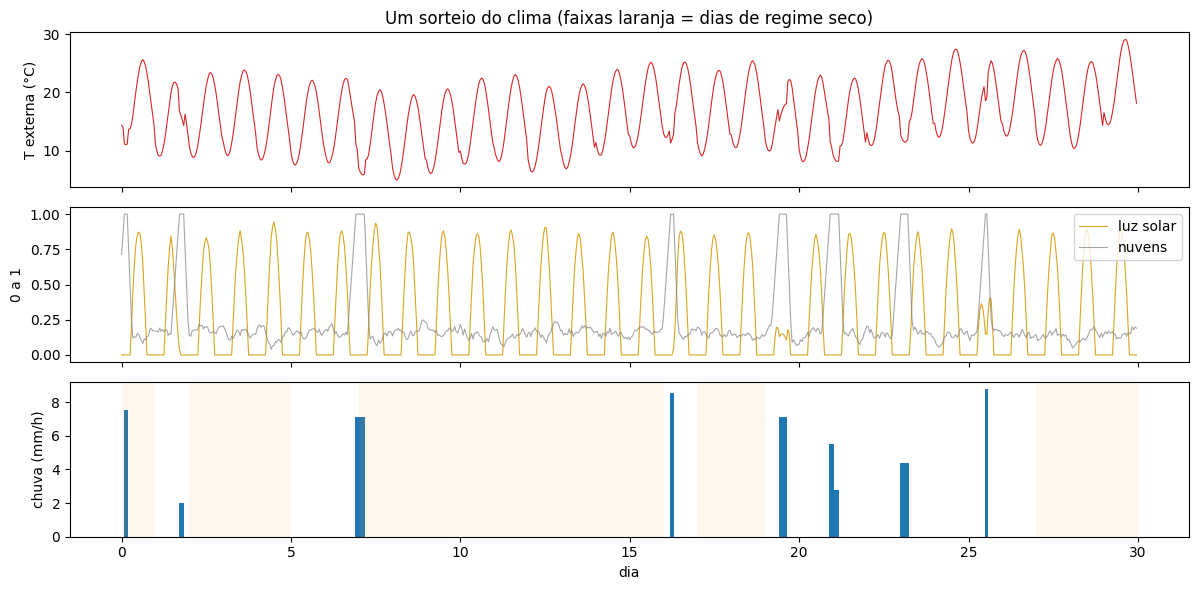

In [ ]:
import matplotlib.pyplot as plt


def plot_clima(clima, dias=30):
    H = dias * 24
    x = np.arange(H) / 24
    fig, ax = plt.subplots(3, 1, figsize=(12, 6), sharex=True)
    ax[0].plot(x, clima["T_ext"][:H], color="tab:red", lw=0.8)
    ax[0].set_ylabel("T externa (°C)")
    ax[1].plot(x, clima["sol"][:H], color="goldenrod", lw=0.8, label="luz solar")
    ax[1].plot(x, clima["nuvem"][:H], color="gray", lw=0.8, alpha=0.7, label="nuvens")
    ax[1].legend(loc="upper right"); ax[1].set_ylabel("0 a 1")
    ax[2].bar(x, clima["chuva"][:H], width=1 / 24, color="tab:blue")
    ax[2].set_ylabel("chuva (mm/h)"); ax[2].set_xlabel("dia")
    for d in np.flatnonzero(~clima["umido"][:dias]):
        ax[2].axvspan(d, d + 1, color="orange", alpha=0.08, lw=0)
    ax[0].set_title("Um sorteio do clima (faixas laranja = dias de regime seco)")
    plt.tight_layout(); plt.show()


def plot_episodio(traj, env, titulo=""):
    """Gráfico 3 do guia: o que o agente fez num episódio."""
    x = np.arange(len(traj)) / 24
    T = np.array([s["T_in"] for s in traj])
    M = np.array([s["M"] for s in traj])
    tanque = np.array([s["tanque"] for s in traj])
    acoes = [env.decodificar(s["acao"]) for s in traj]
    cores = ["tab:orange", "tab:green", "tab:purple", "tab:brown"]

    fig, ax = plt.subplots(4, 1, figsize=(12, 9), sharex=True,
                           gridspec_kw=dict(height_ratios=[2, 2, 1.3, 1.3]))
    # temperatura e a faixa comum
    lo = max(k["T_ideal"][0] for k in env.culturas); hi = min(k["T_ideal"][1] for k in env.culturas)
    ax[0].axhspan(lo, hi, color="green", alpha=0.12, label=f"faixa comum {lo}–{hi} °C")
    ax[0].plot(x, [s["T_ext"] for s in traj], color="gray", lw=0.7, label="externa")
    ax[0].plot(x, T, color="tab:red", lw=1, label="interna")
    ax[0].set_ylabel("°C"); ax[0].legend(loc="upper left", fontsize=8)
    # umidade de cada canteiro com sua faixa
    for i, k in enumerate(env.culturas):
        ax[1].axhspan(*k["M_ideal"], color=cores[i], alpha=0.10)
        ax[1].plot(x, M[:, i], color=cores[i], lw=1, label=k["nome"])
    ax[1].set_ylabel("umidade do substrato (%)"); ax[1].legend(loc="upper right", fontsize=8)
    # tanque, chuva, previsão
    ax[2].fill_between(x, tanque / env.cfg["tanque_cap"], color="tab:blue", alpha=0.3, label="tanque")
    ax[2].plot(x, [s["prev"] for s in traj], color="k", lw=0.6, alpha=0.6, label="previsão")
    ax2b = ax[2].twinx()
    ax2b.bar(x, [s["chuva"] for s in traj], width=1 / 24, color="tab:blue")
    ax2b.set_ylabel("chuva mm/h")
    ax[2].set_ylim(0, 1.05); ax[2].set_ylabel("fração"); ax[2].legend(loc="upper left", fontsize=8)
    # ações
    for i, k in enumerate(env.culturas):
        ax[3].fill_between(x, i * 0.25, i * 0.25 + 0.2 * np.array([a[0][i] for a in acoes]),
                           step="post", color=cores[i], label=f"irriga {k['nome']}")
    ax[3].step(x, 0.6 + 0.35 * np.array([a[1] for a in acoes]), color="tab:red", lw=0.7, label="aquecimento")
    ax[3].step(x, 1.05 + 0.35 * np.array([a[2] for a in acoes]), color="tab:cyan", lw=0.7, label="ventilação")
    ax[3].set_yticks([]); ax[3].legend(loc="upper right", fontsize=7, ncol=4); ax[3].set_xlabel("dia")
    # marca mortes
    j = 0
    for t, s in enumerate(traj):
        for nome in s.get("mortes", []):
            for a_ in ax[:2]:
                a_.axvline(t / 24, color="k", ls="--", lw=1)
            ax[1].text(t / 24, 0.05 + 0.12 * j, f"morre: {nome} ", ha="right", fontsize=8,
                       transform=ax[1].get_xaxis_transform())
            j += 1
    ax[0].set_title(titulo)
    plt.tight_layout(); plt.show()


plot_clima(gerar_clima(np.random.default_rng(7), 720))

## 3. O ambiente `EstufaEnv`

**Estado (11 valores, normalizados para [−1, 1])**, cada um com o sensor que o mediria numa estufa real:

| Variável | Sensor |
|---|---|
| Temperatura interna | termômetro |
| Temperatura externa | termômetro externo |
| Nível do tanque | boia ou ultrassônico |
| Luminosidade | piranômetro |
| Previsão de chuva (48 h) | serviço meteorológico |
| Hora do dia (seno, cosseno) | relógio |
| Umidade do substrato, por canteiro (2) | sensor de umidade do solo |
| Cultura viva/morta, por canteiro (2) | inspeção (no simulador, vem das regras) |

**Ações (36)**: irrigação liga/desliga em cada canteiro (2 × 2) × aquecimento {0, 50, 100%} × ventilação {0, 50, 100%}.

**Física por hora** (simples de propósito):
- temperatura: troca com o exterior pelas paredes e pela ventilação, mais aquecedor, mais sol;
- umidade: irrigação sobe; evaporação desce, maior com sol e calor, proporcional ao `kc` de cada cultura e **menor com substrato seco** (a planta fecha os estômatos). Por isso "segurar" um canteiro perto do limite economiza água;
- tanque: perde o que foi irrigado e ganha a chuva do telhado (até a capacidade).

**Morte**: a cultura morre **na hora** em que temperatura ou umidade passam do limite crítico. Não há contador de "horas sob estresse", que seria informação escondida e quebraria a hipótese de Markov. O canteiro morto sai do jogo; o episódio acaba quando as duas morrem ou aos 30 dias.

**Recompensa por passo:**

| Componente | Valor |
|---|---|
| Cultura viva na faixa ideal | +1 dividido entre as culturas (+0,5 cada) |
| Cultura viva fora da faixa ideal | de +0,3 a 0 (cai até a borda crítica), **nunca negativo** |
| Energia | −0,3 × aquecimento − 0,2 × ventilação (até −0,5) |
| Água | de −0,1 a −1,5 por hora de irrigação plena nos 2 canteiros, maior com tanque baixo |
| Morte de uma cultura | −100 (por cultura) |

Guarda-corpo contra *reward hacking*: uma cultura viva, mesmo sofrendo, nunca rende menos que morta, e cada morte custa −100. Assim "deixar morrer para parar de pagar" nunca compensa; sacrificar um canteiro só vale se isso salvar o outro.

In [ ]:
NIVEIS = (0.0, 0.5, 1.0)   # desligado, médio, máximo


def distancia(x, ideal, crit):
    """0 dentro da faixa ideal; cresce até 1 na borda crítica."""
    lo, hi = ideal
    clo, chi = crit
    if x < lo:
        return min(1.0, (lo - x) / (lo - clo))
    if x > hi:
        return min(1.0, (x - hi) / (chi - hi))
    return 0.0


class EstufaEnv(gym.Env):
    """Estufa com N canteiros (uma cultura cada), clima compartilhado e um
    tanque de água recarregado só pela chuva. 1 passo = 1 hora.

    Ação (Discrete): irrigação liga/desliga por canteiro x aquecimento {0,50,100%}
                     x ventilação {0,50,100%}  ->  2^N * 9 ações (36 para N = 2)
    Observação (Box em [-1, 1]): T interna, T externa, tanque, luz, previsão,
                     seno e cosseno da hora, e para cada canteiro umidade e viva/morta.
    """
    metadata = {"render_modes": []}

    def __init__(self, culturas=CULTURAS, cfg=CONFIG):
        self.culturas, self.cfg = culturas, cfg
        self.n = len(culturas)
        self.max_passos = cfg["dias"] * 24
        self.action_space = spaces.Discrete((2 ** self.n) * 9)
        self.observation_space = spaces.Box(-1.0, 1.0, shape=(7 + 2 * self.n,), dtype=np.float32)

    # ---------- ações ----------
    def decodificar(self, a):
        a = int(a)
        irr = [(a // 9 >> i) & 1 for i in range(self.n)]   # bits: um por canteiro
        aquec = NIVEIS[(a % 9) // 3]
        vent = NIVEIS[a % 3]
        return irr, aquec, vent

    def codificar(self, irr, i_aquec, i_vent):
        """Inverso de decodificar (útil para políticas escritas à mão)."""
        bits = sum(int(b) << i for i, b in enumerate(irr))
        return bits * 9 + i_aquec * 3 + i_vent

    # ---------- observação ----------
    def _obs(self):
        h = self.t % 24
        o = [
            (self.T_in - 20) / 20,
            (self.clima["T_ext"][self.t] - 20) / 20,
            2 * self.tanque / self.cfg["tanque_cap"] - 1,
            2 * self.clima["sol"][self.t] - 1,
            2 * self.prev - 1,
            np.sin(2 * np.pi * h / 24),
            np.cos(2 * np.pi * h / 24),
        ]
        for i in range(self.n):
            o += [self.M[i] / 50 - 1, 2 * self.viva[i] - 1]
        return np.clip(np.array(o, dtype=np.float32), -1, 1)

    def _info(self):
        return dict(t=self.t, T_in=self.T_in, T_ext=float(self.clima["T_ext"][self.t]),
                    M=self.M.copy(), tanque=self.tanque, viva=self.viva.copy(),
                    sol=float(self.clima["sol"][self.t]), chuva=float(self.clima["chuva"][self.t]),
                    prev=self.prev, agua_gasta=self.agua_gasta)

    # ---------- API Gymnasium ----------
    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        rng, c = self.np_random, self.cfg
        self.clima = gerar_clima(rng, self.max_passos + c["prev_horizonte"] + 1, c)
        self.t = 0                                   # começa à meia-noite
        self.T_in = rng.uniform(22, 26)
        self.M = np.array([rng.uniform(*k["M_ini"]) for k in self.culturas])
        self.viva = np.ones(self.n, dtype=bool)
        self.tanque = c["tanque_cap"] * rng.uniform(*c["tanque_ini"])
        self.agua_gasta = 0.0
        self.prev = previsao(self.clima, self.t, rng, c)
        return self._obs(), self._info()

    def step(self, acao):
        c, t = self.cfg, self.t
        irr, aquec, vent = self.decodificar(acao)
        T_ext, sol, chuva = self.clima["T_ext"][t], self.clima["sol"][t], self.clima["chuva"][t]

        # 1) Irrigação: só canteiros vivos; se faltar água, divide o que tem
        irr = np.array(irr) * self.viva
        pedido = irr.sum() * c["irrig_litros"]
        frac = min(1.0, self.tanque / pedido) if pedido > 0 else 0.0
        usado = pedido * frac
        frac_tanque_antes = self.tanque / c["tanque_cap"]
        self.tanque -= usado
        self.agua_gasta += usado
        self.M += irr * frac * c["irrig_umid"]

        # 2) Temperatura: troca com o exterior (paredes + ventilação), aquecedor, sol
        self.T_in += ((c["k_perda"] + c["k_vent"] * vent) * (T_ext - self.T_in)
                      + c["ganho_aquec"] * aquec + c["ganho_solar"] * sol)

        # 3) Evaporação: mais com sol e calor; cada cultura bebe conforme seu kc.
        #    Substrato mais seco perde menos (a planta fecha os estômatos), então
        #    manter o canteiro "no limite" economiza água, ao custo de sair da faixa ideal.
        et = c["et_base"] + c["et_sol"] * sol + c["et_calor"] * max(self.T_in - 20, 0)
        kc = np.array([k["kc"] for k in self.culturas])
        seco = np.array([self.M[i] / k["M_ideal"][1] for i, k in enumerate(self.culturas)])
        self.M -= kc * et * np.clip(seco, 0.2, 1.0)
        self.M = np.clip(self.M, 0, 100)

        # 4) A chuva enche o tanque (telhado -> calha -> tanque)
        self.tanque = min(c["tanque_cap"], self.tanque + chuva * c["area_captacao"])

        # 5) Recompensa
        r = 0.0
        mortes = []
        for i, k in enumerate(self.culturas):
            if not self.viva[i]:
                continue
            fora_crit = not (k["T_crit"][0] < self.T_in < k["T_crit"][1]
                             and k["M_crit"][0] < self.M[i] < k["M_crit"][1])
            if fora_crit:                       # morte instantânea: sem contador escondido
                self.viva[i] = False
                r -= c["pen_morte"]
                mortes.append(k["nome"])
                continue
            d = max(distancia(self.T_in, k["T_ideal"], k["T_crit"]),
                    distancia(self.M[i], k["M_ideal"], k["M_crit"]))
            if d == 0:
                r += c["r_ideal"] / self.n
            else:
                r += c["r_fora"] * (1 - d) / self.n
        r -= c["pen_energia"][0] * aquec + c["pen_energia"][1] * vent
        lo, hi = c["pen_agua"]
        r -= (lo + (hi - lo) * (1 - frac_tanque_antes)) * usado / (self.n * c["irrig_litros"])

        # 6) Avança o relógio
        self.t += 1
        self.prev = previsao(self.clima, self.t, self.np_random, c)
        terminated = not self.viva.any()
        truncated = self.t >= self.max_passos
        info = self._info()
        info["mortes"] = mortes
        return self._obs(), float(r), terminated, truncated, info

In [ ]:
from gymnasium.utils.env_checker import check_env

env = EstufaEnv()
check_env(env)          # confere se reset/step seguem a API do Gymnasium
obs, info = env.reset(seed=0)
print("observação:", obs.shape, "| ações:", env.action_space.n)
print("ação 0 =", env.decodificar(0), "| ação 35 =", env.decodificar(35))

observação: (11,) | ações: 36
ação 0 = ([0, 0], 0.0, 0.0) | ação 35 = ([1, 1], 1.0, 1.0)


/usr/local/lib/python3.13/dist-packages/gymnasium/utils/env_checker.py:496: UserWarning: WARN: Not able to test alternative render modes due to the environment not having a spec. Try instantiating the environment through `gymnasium.make`
  logger.warn(


## 4. Sanidade: linhas de base

Antes do DQN, duas políticas de referência:

- **Aleatória**: sorteia uma das 36 ações. Deve morrer rápido (geralmente encharca um canteiro).
- **Termostato**: regra fixa que mira 26 °C e irriga quando a umidade chega perto do limite de baixo da faixa ideal. **Não olha o tanque nem a previsão**, então não se prepara para a seca.

O DQN precisa bater o termostato. O espaço para isso está justamente no que o termostato ignora: economizar água quando o tanque está baixo e a previsão é seca, e escolher qual canteiro salvar.

In [ ]:
def politica_aleatoria(env, obs, info):
    return env.action_space.sample()


def politica_termostato(env, obs, info):
    """Regra fixa, sem olhar tanque nem previsão:
    mira 26 °C (meio da faixa comum) e irriga quando a umidade
    chega perto do limite de baixo da faixa ideal de cada cultura."""
    T = info["T_in"]
    i_aquec = 2 if T < 23 else (1 if T < 25 else 0)
    i_vent = 2 if T > 28 else (1 if T > 26.5 else 0)
    irr = [int(info["M"][i] < k["M_ideal"][0] + 5) for i, k in enumerate(env.culturas)]
    return env.codificar(irr, i_aquec, i_vent)


def rodar(env, politica, n_episodios=100, seed=0, guardar=False):
    """Roda episódios e devolve métricas por episódio (e, se pedido, a trajetória do último)."""
    res, traj = [], []
    for ep in range(n_episodios):
        obs, info = env.reset(seed=seed + ep)
        G, passos, done = 0.0, 0, False
        traj = []
        while not done:
            a = politica(env, obs, info)
            obs, r, term, trunc, info = env.step(a)
            G += r
            passos += 1
            done = term or trunc
            if guardar:
                traj.append(dict(info, acao=a, r=r))
        res.append(dict(retorno=G, passos=passos, agua=info["agua_gasta"],
                        vivas=int(info["viva"].sum()),
                        **{f"viva_{k['nome']}": bool(info["viva"][i]) for i, k in enumerate(env.culturas)}))
    return res, traj


def resumo(nome, res, env):
    r = np.array([x["retorno"] for x in res])
    linha = f"{nome:12s} retorno {r.mean():8.1f} ± {r.std():6.1f} | água {np.mean([x['agua'] for x in res]):6.0f} L"
    for k in env.culturas:
        linha += f" | {k['nome']} sobrevive {100*np.mean([x['viva_'+k['nome']] for x in res]):5.1f}%"
    print(linha)

In [ ]:
env = EstufaEnv()
res_aleat, _ = rodar(env, politica_aleatoria, n_episodios=100)
res_termo, _ = rodar(env, politica_termostato, n_episodios=100)
resumo("aleatória", res_aleat, env)
resumo("termostato", res_termo, env)

aleatória    retorno   -202.9 ±    1.2 | água    214 L | milho sobrevive   0.0% | feijão-caupi sobrevive   0.0%
termostato   retorno    424.7 ±  201.5 | água   2704 L | milho sobrevive  68.0% | feijão-caupi sobrevive  75.0%


Um episódio do termostato, com seca. É o mesmo formato de gráfico que vamos usar para o agente treinado (gráfico 3 do guia): temperatura com a faixa comum, umidade de cada canteiro com sua faixa ideal, tanque com chuva e previsão, e as ações embaixo.

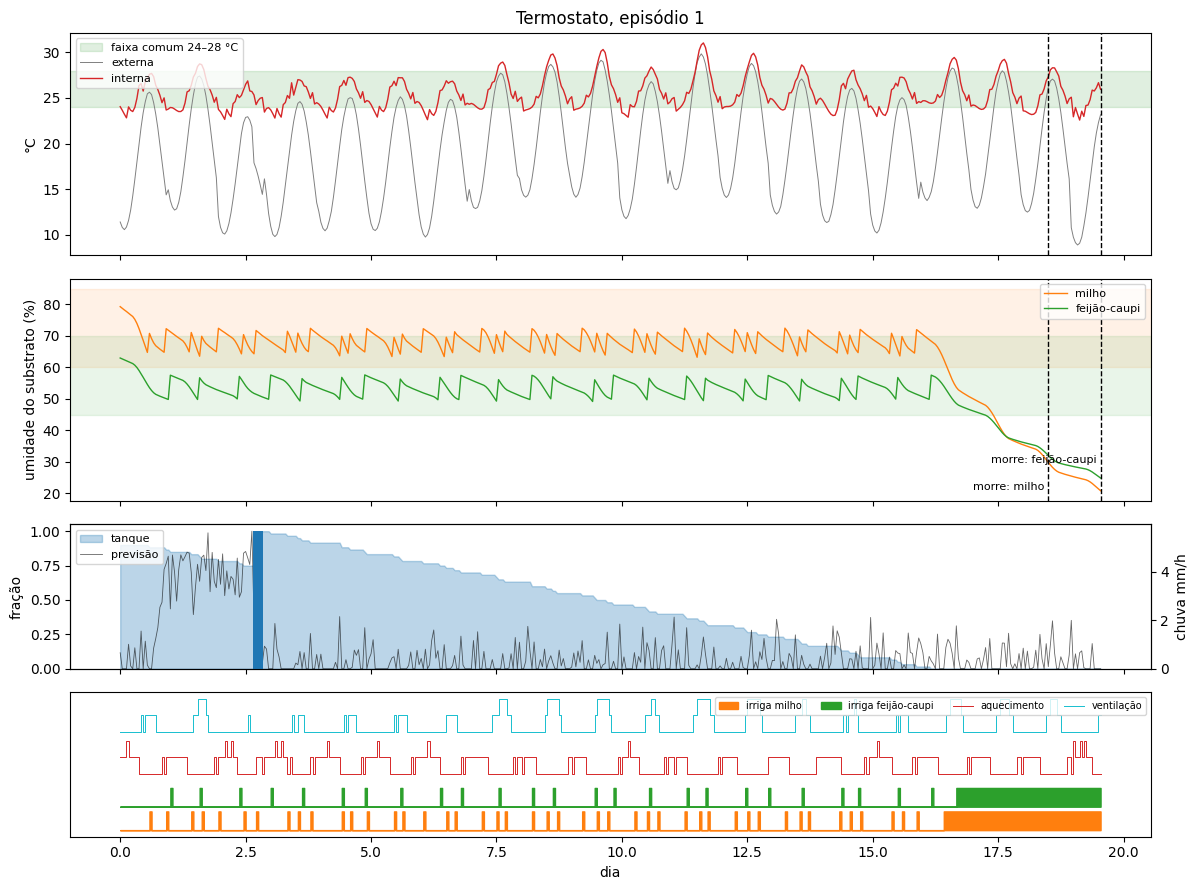

In [ ]:
# procura um episódio em que o termostato perde alguma cultura (para ver a seca acontecendo)
seed_seca = next(i for i, r in enumerate(res_termo) if r["vivas"] < 2)
_, traj = rodar(env, politica_termostato, n_episodios=1, seed=seed_seca, guardar=True)
plot_episodio(traj, env, f"Termostato, episódio {seed_seca}")